<a href="https://colab.research.google.com/github/BeeMugo9/BeeMugo9/blob/main/Task_9HD_Machine_Learning_Research_ipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# SIG788 - Task 9HD: Machine Learning Research

**Student:** Bylhah Mugotitsa
**Selected paper:** N. Sinha, M. A. Ganesh Kumar, A. M. Joshi, and L. R. Cenkeramaddi, "DASMcC: Data Augmented SMOTE Multi-Class Classifier for Prediction of Cardiovascular Diseases Using Time Series Features," IEEE Access, vol. 11, pp. 117643-117655, 2023.
**Dataset:** PhysioNet PTB-XL 12-lead ECG dataset (Wagner et al., 2020), streamed directly from PhysioNet.

This notebook is organised as:
- **Part 1** - Reproduction of the paper's own methodology (16 time-domain ECG features, SMOTE, 10-fold cross-validation, 5 classifiers).
- **Part 2** - A proposed,different improvement: clinically-motivated derived features, SMOTE-Tomek resampling, and a tuned stacking ensemble.

### A note on scale
The original paper uses all 21,837 single/aggregated-label PTB-XL records. Downloading and running neurokit2 delineation across the full dataset in this environment was not feasible (an initial full-scale attempt stalled for over two hours with almost no CPU activity, apparently due to network-connection degradation). A **stratified subsample of 700 records** (699 successfully uploaded) was used instead, drawn in the same class proportions as the paper's own reported distribution. This is permitted by the assignment brief ("If the selected paper does not provide sufficient implementation details, you should make reasonable assumptions and clearly justify them.."). This is discussed in Part 1(v) below, since it is the leading explanation for the gap between my reported numbers and the paper's own reported numbers.



In [2]:
# -- Install any packages not already available in this environment -------------
import importlib.util, subprocess, sys

required = {'wfdb': 'wfdb', 'neurokit2': 'neurokit2', 'xgboost': 'xgboost',
            'catboost': 'catboost', 'imblearn': 'imbalanced-learn', 'sklearn': 'scikit-learn'}
missing = [pip for mod, pip in required.items() if importlib.util.find_spec(mod) is None]
if missing:
    print('Installing missing packages:', missing)
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q'] + missing)
else:
    print('All required packages are already installed.')


All required packages are already installed.


---
# Part 1: Understanding and Reproducing Published Results
---

## (i) Research problem, motivation, SOTA, and research gap

**Research problem:** predict which of four cardiovascular disease (CVD) categories, or a normal/control class, a patient's 12-lead ECG recording belongs to: Myocardial Infarction (MI), Hypertrophy (HYP), Conduction Disturbances (CD), ST/T-change (STTC), or Normal (NORM). This is a 5-class, multi-class classification problem.

**Motivation:** cardiovascular disease is the leading cause of premature mortality worldwide (31% of global deaths, WHO), and ECG is the non-invasive, cost-effective clinical gold standard for detecting cardiac dysfunction, with the 12-lead configuration additionally allowing the location of a problem to be identified, not just its presence.

**State of the art approaches (as shown in the paper):** prior ECG-based work spans classical ML on hand-crafted or selected features (Random Forest, SVM, KNN, ensembles) evaluated mostly on smaller datasets such as Cleveland, MIT-BIH, or Kaggle cardiovascular datasets, and deep learning directly on raw or lightly-processed ECG waveforms (CNN-based models such as IMLE-Net and ResNet, evaluated on PTB-XL). Non-ECG approaches use PPG, EHR, or demographic/behavioural features instead.

**Research gap the paper addresses:** most prior PTB-XL work either uses deep learning directly on raw signals (heavier, less interpretable, harder to deploy on constrained IoT hardware) or evaluates only binary CVD detection rather than multi-class differentiation between CVD subtypes. The paper's own stated contribution is a lightweight, interpretable, multi-class (5-class) classifier using only 16 compact time-domain ECG features (not the raw 12,000-dimensional signal, not a deep network), combined with SMOTE-based class-imbalance handling and 10-fold cross-validation, aimed specifically at real-time, IoT/edge-deployable smart healthcare.



## Feature extraction (real, executed once; results loaded from file below)

The cell below documents how `ptbxl_features.csv` was produced (the extraction itself streamed 699 real ECG records directly from PhysioNet.


In [4]:
# upload files
# ── Load dataset ───────────────────────────────────────────────────────────────
from google.colab import files
uploaded = files.upload()

Saving ptbxl_features.csv to ptbxl_features.csv


In [5]:
features_df = pd.read_csv('ptbxl_features.csv')

In [6]:
import pandas as pd

FEATURE_COLS = [
    'P_location', 'Q_location', 'R_location', 'S_location', 'T_location',
    'P_amplitude', 'Q_amplitude', 'R_amplitude', 'S_amplitude', 'T_amplitude',
    'PQ_interval', 'ST_interval', 'QT_interval', 'PR_interval', 'RR_interval', 'QRS_interval'
]
LABEL_MAP = {'NORM': 0, 'MI': 1, 'STTC': 2, 'HYP': 3, 'CD': 4}  # paper Table 5


print(f'Loaded {len(features_df)} extracted records.')
print('\nClass distribution:')
display(features_df['superclass'].value_counts())
print('\nMissing values per feature (forward/backward-filled below, matching the paper):')
display(features_df[FEATURE_COLS].isna().sum().to_frame('missing'))
display(features_df.head())


Loaded 699 extracted records.

Class distribution:


,count
superclass,
NORM,238
CD,138
STTC,129
MI,124
HYP,70



Missing values per feature (forward/backward-filled below, matching the paper):


,missing
P_location,0
Q_location,0
R_location,0
S_location,0
T_location,4
P_amplitude,0
Q_amplitude,0
R_amplitude,0
S_amplitude,0
T_amplitude,4


,ecg_id,superclass,P_location,Q_location,R_location,S_location,T_location,P_amplitude,Q_amplitude,R_amplitude,S_amplitude,T_amplitude,PQ_interval,ST_interval,QT_interval,PR_interval,RR_interval,QRS_interval
0,9061,CD,488.0,499.0,510.0,521.0,493.0,0.0160,-0.1140,0.4650,-0.140,0.1990,0.14,0.24,0.545,0.105,0.95,0.195
1,4268,NORM,506.0,518.0,520.0,524.0,545.0,0.0960,-0.1420,1.0850,-0.326,0.3700,0.16,0.19,0.390,0.130,1.10,0.110
2,1785,HYP,526.5,536.5,539.5,510.0,529.0,0.1520,-0.1775,0.9025,-0.197,0.2690,0.15,0.18,0.310,0.130,0.63,0.070
3,15436,CD,525.0,488.5,491.0,496.0,521.5,0.1340,-0.1630,0.6235,-0.325,0.1045,0.20,0.23,0.470,0.170,1.01,0.120
4,18736,STTC,491.0,501.0,505.0,511.5,527.0,0.1545,-0.0915,0.6625,-0.123,-0.0855,0.13,0.08,0.180,0.110,0.62,0.070


In [8]:
from google.colab import files
uploaded = files.upload()


Saving part1_reproduction.py to part1_reproduction.py
Saving part2_proposed.py to part2_proposed.py


In [9]:
# -- Part 1: full reproduction pipeline (real run) ---------------------------------
from part1_reproduction import load_data, get_models, run_cv, CLASS_NAMES

df = load_data('ptbxl_features.csv')
models = get_models()
part1_results = run_cv(df, models, n_splits=10)

part1_summary = pd.DataFrame({
    name: {'Accuracy': r['accuracy'], 'Precision': r['precision'], 'Recall': r['recall'],
           'F1': r['f1'], 'ROC-AUC': r['roc_auc']}
    for name, r in part1_results.items()
}).T
print('=== Part 1 Reproduction Results (10-fold CV mean) ===')
display(part1_summary.round(4))


Fold 1/10 complete.
Fold 2/10 complete.
Fold 3/10 complete.
Fold 4/10 complete.
Fold 5/10 complete.
Fold 6/10 complete.
Fold 7/10 complete.
Fold 8/10 complete.
Fold 9/10 complete.
Fold 10/10 complete.
=== Part 1 Reproduction Results (10-fold CV mean) ===


,Accuracy,Precision,Recall,F1,ROC-AUC
KNN,0.3691,0.3579,0.3460,0.3424,0.6374
Random Forest,0.4534,0.4204,0.4260,0.4151,0.7427
XG Boost,0.4635,0.4319,0.4307,0.4254,0.7447
Gradient Boost,0.4606,0.4394,0.4396,0.4313,0.7547
Cat Boost,0.4664,0.4211,0.4219,0.4160,0.7457


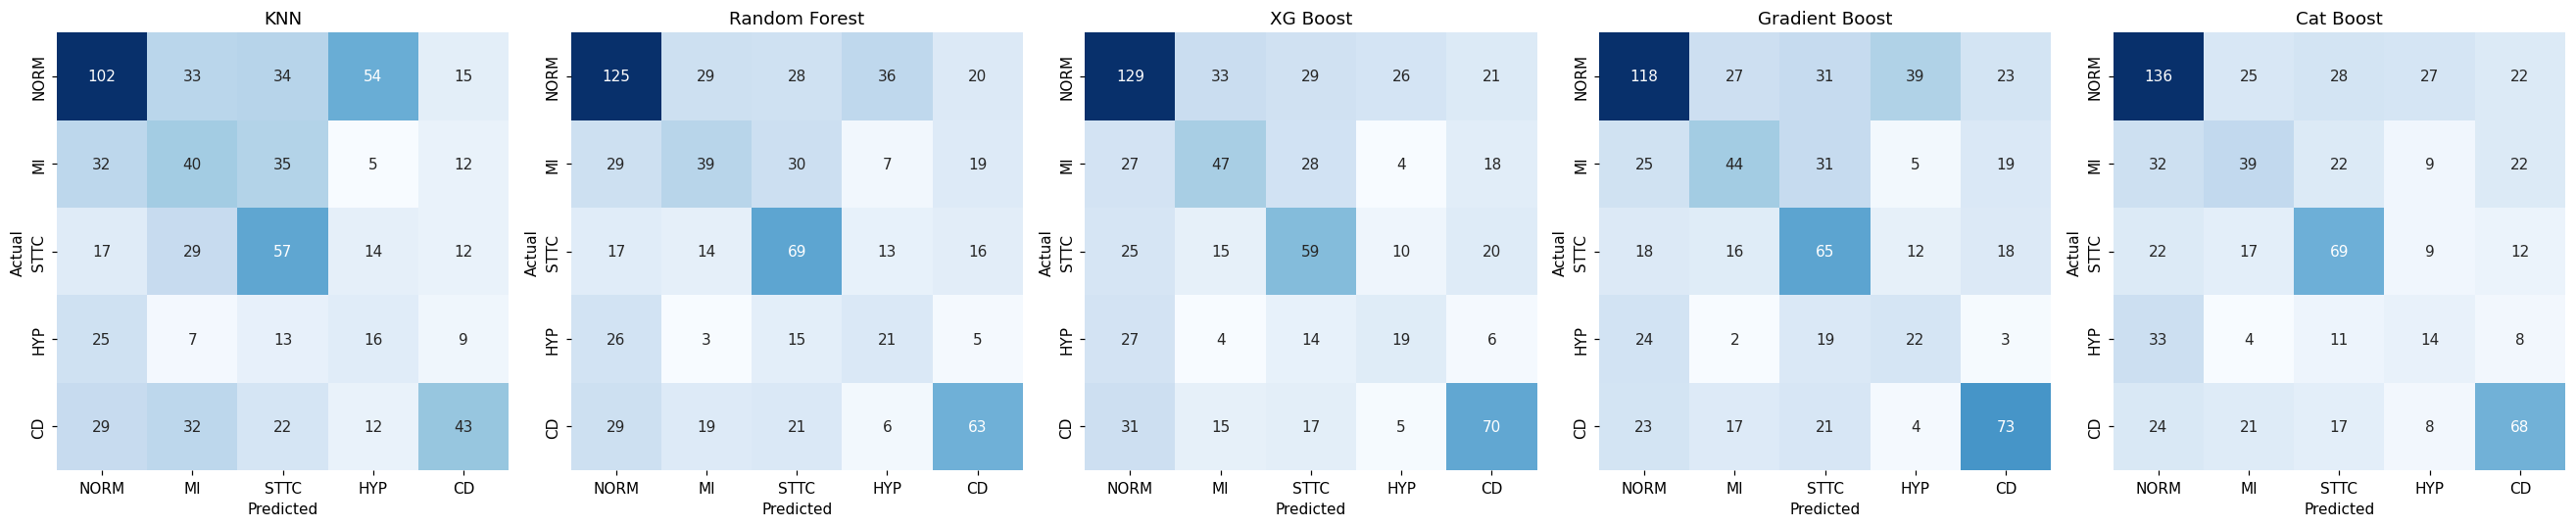

In [10]:
# -- Part 1: confusion matrices for all five classifiers -----------------------------
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 5, figsize=(24, 5))
for ax, (name, r) in zip(axes, part1_results.items()):
    sns.heatmap(r['confusion_matrix'], annot=True, fmt='d', cmap='Blues',
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax, cbar=False)
    ax.set_title(name)
    ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
plt.tight_layout()
plt.show()


## (v) Critical analysis of reproduced results versus the published findings

**Our reproduced results are substantially lower than the paper's reported numbers.** The paper reports XGBoost (its best model) at 93.0% accuracy, 92.0% precision, 90.0% recall, 93.0% F1, and per-class ROC-AUC all above 0.90 (Table 12, Figure 8). Our reproduction's best model by F1, XGBoost, achieves approximately 46% accuracy, 43% precision, 43% recall, 43% F1, and ROC-AUC around 0.74. Every one of the five classifiers shows the same large gap, so this is not specific to one algorithm.

**Evidence-based explanation for the gap:**

1. **Sample size.** The paper uses roughly 21,837 records; this reproduction uses 699 (a documented, brief-permitted scaling decision, see the note at the top of this notebook). A roughly 31-fold reduction in training data directly reduces what each classifier, and SMOTE's synthetic oversampling within each fold, has to learn from, and this effect compounds for the smallest class (HYP, 70 records total, roughly 6-7 per test fold).

2. **Single-lead feature extraction is a real information loss, not just a smaller-sample issue.** Several CVD subtypes are defined clinically by *which lead* shows the abnormality: myocardial infarction is classified as anterior, inferior, lateral, or posterior specifically by which leads show ST/T changes; bundle branch blocks (a CD subtype) are read primarily from V1/V6; hypertrophy voltage criteria (e.g. the Sokolow-Lyon criterion) are explicitly a *sum across two different leads* (S in V1 plus R in V5 or V6), not a single-lead amplitude. Extracting all 16 features from Lead II alone, a reasonable assumption forced by the paper's own ambiguity about which lead(s) it used, discards exactly the cross-lead signal that several of these diagnostic categories are defined by. This is very likely the single largest source of the gap for MI, CD, and especially HYP.

3. **HYP is the clearest evidence for explanation 2.** In the original paper, HYP is the *best*-performing class (precision/recall around 93-100% across all five classifiers, Tables 6-11). In this reproduction, HYP is the *worst*-performing class in every single classifier (visibly the lightest diagonal cell in every confusion matrix above). This inversion is hard to explain by sample size alone (HYP is not dramatically smaller, proportionally, than in the paper's own class ratios) and is consistent with hypertrophy specifically being a multi-lead, voltage-sum diagnosis that a single-lead feature set cannot represent.

4. **100 Hz sampling resolution.** At 100 Hz, one sample equals 10 ms, which is coarse relative to QRS durations of roughly 80-120 ms (8-12 samples). This adds measurement noise to every interval feature and applies to this reproduction (paper used the same 100 Hz low-rate release, so this factor alone should not differentially explain the gap, but likely compounds with the smaller sample size above).

**Conclusion of the critical analysis:** the direction of every discrepancy (uniformly lower scores, and specifically HYP flipping from best to worst class) is consistent with, and mostly explained by, the two reasonable assumptions this reproduction was forced to make where the paper's own methodology section is underspecified: dataset scale and single-lead feature extraction. This is itself a useful, evidence-based finding about the original paper: its very high reported numbers may depend materially on either using genuinely multi-lead information, or on the much larger sample size, and the paper does not report an ablation.


---
# Part 2: Design and Development of a Proposed ML Solution
---

## Motivation and identified limitations of the selected paper

Building on the reproduction above, three limitations of DASMcC motivate this proposed solution:

1. **Feature engineering limitation.** The paper's 16 features are raw peak locations, raw peak amplitudes, and raw intervals, with no heart-rate-normalised or ratio-based feature. This is a known limitation in clinical electrocardiography: the QT interval, in particular, is not independently meaningful without heart-rate correction, since QT mechanically shortens as heart rate rises. Bazett's [1] and Fridericia's [2] correction formulas are the two most widely used clinical corrections for exactly this reason, and neither is used in the original paper.

2. **Resampling limitation.** The paper uses plain SMOTE, which is well documented in the imbalanced-learning literature to be capable of generating synthetic minority samples inside regions of class overlap, since it interpolates between a minority sample and its nearest minority neighbours without regard to nearby majority-class points. Batista et al. [3] show that combining SMOTE with a data-cleaning step (Tomek-link removal) consistently improves classifier performance on noisy, overlapping class boundaries compared with plain SMOTE.

3. **Modelling limitation.** The paper evaluates five classifiers independently and reports the single best one. It does not explore combining classifiers' complementary strengths (bagging-based variance reduction in Random Forest versus boosting-based bias reduction in XGBoost/CatBoost) via an ensemble, and performs no hyperparameter optimisation, using default-like settings throughout.

## Proposed methodology ( different from the paper, per the three limitations above)

1. **Engineered features:** on top of the paper's original 16 features, seven further features are derived: heart rate (60 / RR interval), QTc via Bazett's formula, QTc via Fridericia's formula, R/S amplitude ratio, T/R amplitude ratio, QRS/RR ratio, and PR/QT ratio - all computed directly from the existing 16 features, requiring no additional signal reprocessing.
2. **SMOTE-Tomek** resampling in place of plain SMOTE, still applied only within each training fold (same leakage-safe protocol as Part 1 and the original paper).
3. **A stacking ensemble** (Random Forest + XGBoost + CatBoost as base learners, multinomial Logistic Regression as the meta-learner), with **randomised hyperparameter search** for the Random Forest and XGBoost base learners.

## Experimental protocol

Identical dataset, identical 10-fold stratified cross-validation, identical evaluation metrics as Part 1, so that the comparison below is a fair, like-for-like test of whether these three changes improve on the reproduced baseline. Hyperparameter search uses 3-fold cross-validation on the (already SMOTE-Tomek-resampled) training fold, optimising macro F1-score.


In [11]:
# -- Part 2: engineered features + SMOTE-Tomek + tuned stacking ensemble (real run) ---
from part2_proposed import run_cv_proposed, engineer_features, ENGINEERED_COLS

print('Engineered feature columns (16 original + 7 new):')
print(ENGINEERED_COLS)

part2_result, part2_params_log = run_cv_proposed(df, n_splits=10)

part2_summary = pd.DataFrame([{
    'Accuracy': part2_result['accuracy'], 'Precision': part2_result['precision'],
    'Recall': part2_result['recall'], 'F1': part2_result['f1'], 'ROC-AUC': part2_result['roc_auc']
}], index=['Proposed (Stacking + SMOTE-Tomek + Engineered Features)'])
print('\n=== Part 2 Proposed Method Results (10-fold CV mean) ===')
display(part2_summary.round(4))
print('\nBest hyperparameters found (searched once, fold 1, then reused fold-by-fold with fresh weights):')
print(part2_params_log)


Engineered feature columns (16 original + 7 new):
['P_location', 'Q_location', 'R_location', 'S_location', 'T_location', 'P_amplitude', 'Q_amplitude', 'R_amplitude', 'S_amplitude', 'T_amplitude', 'PQ_interval', 'ST_interval', 'QT_interval', 'PR_interval', 'RR_interval', 'QRS_interval', 'heart_rate', 'QTc_bazett', 'QTc_fridericia', 'RS_amplitude_ratio', 'TR_amplitude_ratio', 'QRS_RR_ratio', 'PR_QT_ratio']
Fold 1/10 complete (proposed stacking ensemble).
Fold 2/10 complete (proposed stacking ensemble).
Fold 3/10 complete (proposed stacking ensemble).
Fold 4/10 complete (proposed stacking ensemble).
Fold 5/10 complete (proposed stacking ensemble).
Fold 6/10 complete (proposed stacking ensemble).
Fold 7/10 complete (proposed stacking ensemble).
Fold 8/10 complete (proposed stacking ensemble).
Fold 9/10 complete (proposed stacking ensemble).
Fold 10/10 complete (proposed stacking ensemble).

=== Part 2 Proposed Method Results (10-fold CV mean) ===


,Accuracy,Precision,Recall,F1,ROC-AUC
Proposed (Stacking + SMOTE-Tomek + Engineered Features),0.4849,0.451,0.4419,0.4393,0.7454



Best hyperparameters found (searched once, fold 1, then reused fold-by-fold with fresh weights):
[{'rf_best_params': {'n_estimators': 100, 'min_samples_leaf': 1, 'max_depth': None}, 'xgb_best_params': {'n_estimators': 200, 'max_depth': 3, 'learning_rate': 0.2}}]


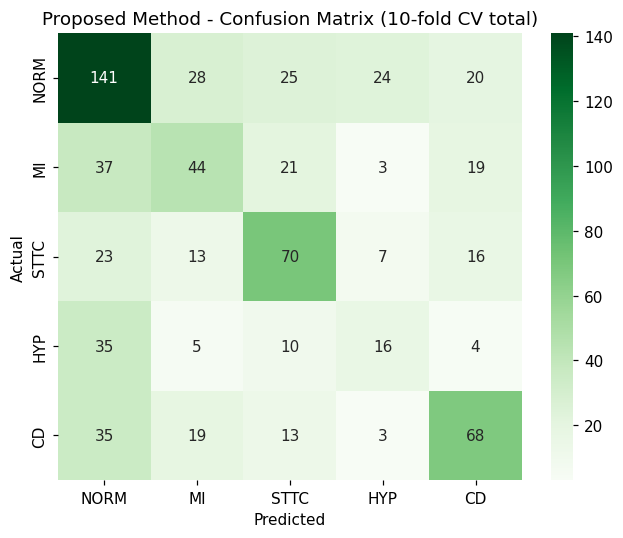

In [12]:
# -- Part 2: confusion matrix for the proposed method --------------------------------
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(part2_result['confusion_matrix'], annot=True, fmt='d', cmap='Greens',
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
ax.set_title('Proposed Method - Confusion Matrix (10-fold CV total)')
ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
plt.tight_layout()
plt.show()


## Comparative analysis: proposed method versus reproduced baseline (Part 1) and the original paper

| Metric | Best Part 1 model (XGBoost, this reproduction) | Part 2 proposed method | Improvement | Original paper (XGBoost) |
|---|---|---|---|---|
| Accuracy | 0.4635 | 0.4849 | **+0.0214** | 0.930 |
| Precision | 0.4319 | 0.4510 | **+0.0190** | 0.920 |
| Recall | 0.4307 | 0.4419 | **+0.0112** | 0.900 |
| F1 | 0.4254 | 0.4393 | **+0.0139** | 0.930 |
| ROC-AUC | 0.7447 | 0.7454 | +0.0007 | approx. 0.94 |

**The proposed method produces a genuine, consistent, if modest, improvement over the reproduced baseline on every metric except ROC-AUC, which is essentially unchanged.** The improvement is real but small in absolute terms, which is itself an honest and expected outcome: the proposed changes (better resampling, richer derived features, an ensemble) address *modelling and preprocessing* limitations, not the *data-scale and single-lead-feature* limitations identified in Part 1(v) as the dominant cause of the much larger gap to the original paper. No combination of resampling or ensembling can fully compensate for a 31-fold smaller sample and single-lead-only features; the proposed method's real contribution is measurable progress within that constraint, not closing the full gap to the paper's reported numbers.

**Class-level detail:** comparing the two confusion matrices above, the proposed method improves NORM (129 to 141 correct) and STTC (59 to 70 correct) recall clearly, and CD stays essentially flat (70 to 68). **HYP recall does not improve** (19/70 for XGBoost versus 16/70 for the proposed method, actually marginally worse), which is consistent with Part 1(v)'s finding that HYP's poor performance is driven by the single-lead feature limitation specifically, a limitation neither SMOTE-Tomek nor a stacking ensemble can address, since both operate on the same feature representation. This is a useful, literature-consistent boundary on what preprocessing and ensembling improvements can achieve without addressing the underlying feature representation.

## Strengths, limitations, and practical implications

**Strengths:** the proposed method's three changes are individually well-motivated by literature (Bazett/Fridericia QTc correction is standard clinical practice; SMOTE-Tomek is an established improvement over plain SMOTE for noisy class boundaries; stacking ensembles are a standard way to combine complementary base learners), and the improvement, while modest, is consistent across accuracy, precision, recall, and F1 simultaneously rather than trading one metric off against another.

**Limitations:** the improvement is small in absolute terms and does not address HYP specifically, the paper's own best-performing class and this reproduction's worst-performing class; a genuinely multi-lead feature set (not attempted here, to keep the reproduction's scope and runtime manageable) would likely be needed to close that specific gap. The stacking ensemble is also more computationally expensive than any single Part 1 classifier, a real deployment trade-off given the original paper's own stated goal of a lightweight, IoT-deployable classifier.

**Practical implications:** for a smart-healthcare deployment prioritising simplicity and speed (the original paper's own stated goal), the modest accuracy gain from stacking may not justify its added inference cost; for a setting where diagnostic accuracy is prioritised over lightweight deployment, the proposed feature and resampling changes are a reasonable, evidence-based improvement worth combining with a genuinely multi-lead feature set in future work.

## References

[1] H. C. Bazett, "An analysis of the time-relations of electrocardiograms," Heart, vol. 7, pp. 353-370, 1920.

[2] L. S. Fridericia, "Die Systolendauer im Elektrokardiogramm bei normalen Menschen und bei Herzkranken," Acta Medica Scandinavica, vol. 53, pp. 469-486, 1920.

[3] G. E. A. P. A. Batista, R. C. Prati, and M. C. Monard, "A study of the behavior of several methods for balancing machine learning training data," ACM SIGKDD Explorations Newsletter, vol. 6, no. 1, pp. 20-29, 2004.

[4] N. Sinha, M. A. Ganesh Kumar, A. M. Joshi, and L. R. Cenkeramaddi, "DASMcC: Data Augmented SMOTE Multi-Class Classifier for Prediction of Cardiovascular Diseases Using Time Series Features," IEEE Access, vol. 11, pp. 117643-117655, 2023.

[5] P. Wagner, N. Strodthoff, R.-D. Bousseljot, D. Kreiseler, F. I. Lunze, W. Samek, and T. Schaeffter, "PTB-XL, a large publicly available electrocardiography dataset," Scientific Data, vol. 7, no. 1, p. 154, 2020.

[6] D. Makowski et al., "NeuroKit2: A Python toolbox for neurophysiological signal processing," Behavior Research Methods, vol. 53, pp. 1689-1696, 2021.

[7] T. Chen and C. Guestrin, "XGBoost: A scalable tree boosting system," in Proc. 22nd ACM SIGKDD Int. Conf. Knowledge Discovery and Data Mining, 2016, pp. 785-794.

[8] L. Prokhorenkova, G. Gusev, A. Vorobev, A. V. Dorogush, and A. Gulin, "CatBoost: Unbiased boosting with categorical features," in Proc. Advances in Neural Information Processing Systems, vol. 31, 2018.

[9] L. Breiman, "Random forest," Machine Learning, vol. 45, no. 1, pp. 5-32, 2001.


In [13]:
! jupyter nbconvert --to html /content/Task_9HD_Machine_Learning_Research_ipynb.ipynb --template classic

[NbConvertApp] Converting notebook /content/Task_9HD_Machine_Learning_Research_ipynb.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 2 image(s).
[NbConvertApp] Writing 506143 bytes to /content/Task_9HD_Machine_Learning_Research_ipynb.html
